In [ ]:
!pip install sqlalchemy pandas matplotlib seaborn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

print("✅ All libraries loaded")

✅ All libraries loaded


In [ ]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)
print(f"✅ Dataset loaded: {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

✅ Dataset loaded: 7043 rows × 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print("=== COLUMN NAMES ===")
print(df.columns.tolist())

print("\n=== DATA TYPES ===")
print(df.dtypes)

print("\n=== MISSING VALUES ===")
print(df.isnull().sum())

print("\n=== CHURN SPLIT ===")
print(df['Churn'].value_counts())
print(f"Churn rate: {df['Churn'].value_counts(normalize=True)['Yes']*100:.1f}%")

=== COLUMN NAMES ===
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

=== DATA TYPES ===
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

=== MISSING VALUES ===
customerI

In [ ]:
# TotalCharges has spaces instead of NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Drop rows where TotalCharges is null (new customers with 0 tenure)
df.dropna(subset=['TotalCharges'], inplace=True)

# Convert Churn to 0/1 (needed for SQL aggregations later)
df['ChurnFlag'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Clean up column names (remove spaces)
df.columns = df.columns.str.strip()

print(f"✅ Clean dataset: {df.shape[0]} rows")
print(f"Churn rate: {df['ChurnFlag'].mean()*100:.1f}%")

✅ Clean dataset: 7032 rows
Churn rate: 26.6%


In [ ]:
# local SQLite database right in Colab
engine = create_engine('sqlite:///telecom_churn.db')

# Load the full dataset as a SQL table
df.to_sql('customers', engine, if_exists='replace', index=False)

print("✅ Data loaded into SQLite database → table: 'customers'")
print(f"Rows in DB: {pd.read_sql('SELECT COUNT(*) as total FROM customers', engine).iloc[0,0]}")

✅ Data loaded into SQLite database → table: 'customers'
Rows in DB: 7032


In [ ]:
# preview
query = """
SELECT
    Contract,
    COUNT(*) as total_customers,
    SUM(ChurnFlag) as churned,
    ROUND(AVG(ChurnFlag) * 100, 1) as churn_rate_pct,
    ROUND(AVG(MonthlyCharges), 2) as avg_monthly_charge
FROM customers
GROUP BY Contract
ORDER BY churn_rate_pct DESC
"""

result = pd.read_sql(query, engine)
print(result)

         Contract  total_customers  churned  churn_rate_pct  \
0  Month-to-month             3875     1655            42.7   
1        One year             1472      166            11.3   
2        Two year             1685       48             2.8   

   avg_monthly_charge  
0               66.40  
1               65.08  
2               60.87  


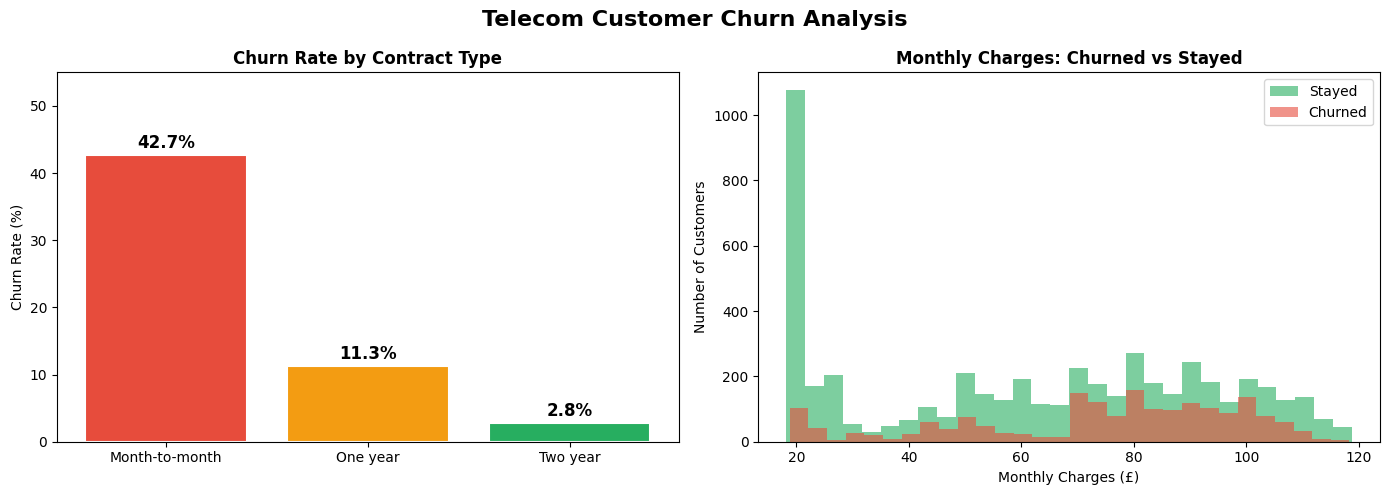

✅ Chart saved


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Telecom Customer Churn Analysis', fontsize=16, fontweight='bold')

# Chart 1: Churn rate by contract
contract_churn = df.groupby('Contract')['ChurnFlag'].mean() * 100
bars = axes[0].bar(contract_churn.index, contract_churn.values,
                    color=['#e74c3c','#f39c12','#27ae60'], edgecolor='white', linewidth=1.5)
axes[0].set_title('Churn Rate by Contract Type', fontweight='bold')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].set_ylim(0, 55)
for bar, val in zip(bars, contract_churn.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{val:.1f}%', ha='center', fontweight='bold', fontsize=12)

# Chart 2: Monthly charges - churned vs not
axes[1].hist(df[df['ChurnFlag']==0]['MonthlyCharges'], bins=30, alpha=0.6,
             label='Stayed', color='#27ae60')
axes[1].hist(df[df['ChurnFlag']==1]['MonthlyCharges'], bins=30, alpha=0.6,
             label='Churned', color='#e74c3c')
axes[1].set_title('Monthly Charges: Churned vs Stayed', fontweight='bold')
axes[1].set_xlabel('Monthly Charges (£)')
axes[1].set_ylabel('Number of Customers')
axes[1].legend()

plt.tight_layout()
plt.savefig('churn_analysis_1.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Chart saved")

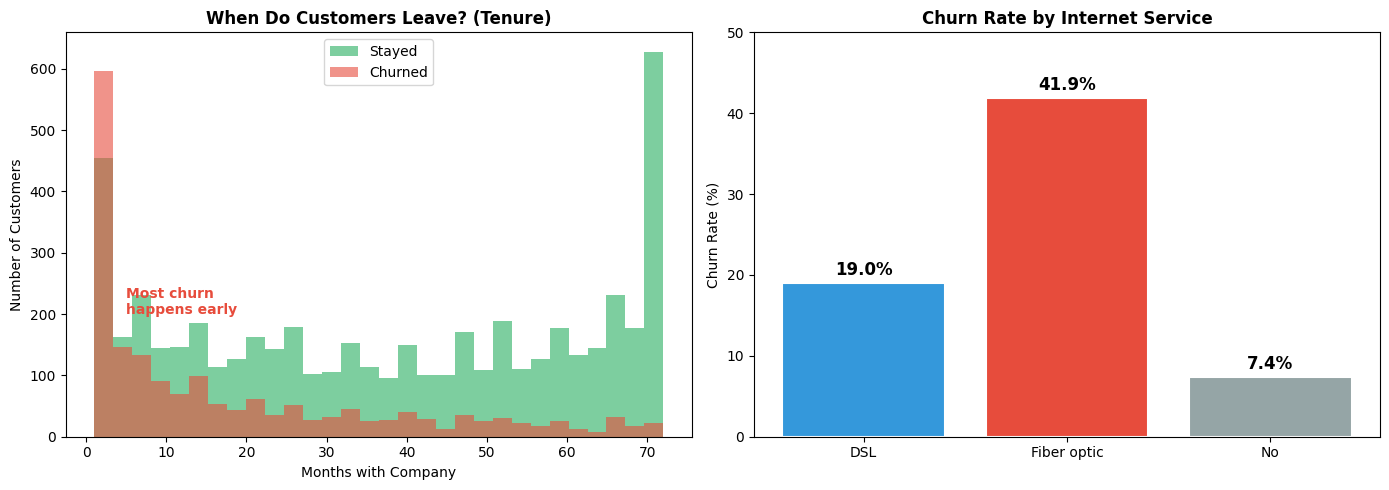

✅ Chart saved


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 3: Tenure distribution
axes[0].hist(df[df['ChurnFlag']==0]['tenure'], bins=30, alpha=0.6,
             label='Stayed', color='#27ae60')
axes[0].hist(df[df['ChurnFlag']==1]['tenure'], bins=30, alpha=0.6,
             label='Churned', color='#e74c3c')
axes[0].set_title('When Do Customers Leave? (Tenure)', fontweight='bold')
axes[0].set_xlabel('Months with Company')
axes[0].set_ylabel('Number of Customers')
axes[0].legend()
axes[0].annotate('Most churn\nhappens early', xy=(5, 200), fontsize=10,
                  color='#e74c3c', fontweight='bold')

# Chart 4: Internet service churn
internet_churn = df.groupby('InternetService')['ChurnFlag'].mean() * 100
bars2 = axes[1].bar(internet_churn.index, internet_churn.values,
                     color=['#3498db','#e74c3c','#95a5a6'], edgecolor='white', linewidth=1.5)
axes[1].set_title('Churn Rate by Internet Service', fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_ylim(0, 50)
for bar, val in zip(bars2, internet_churn.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{val:.1f}%', ha='center', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.savefig('churn_analysis_2.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Chart saved")

In [ ]:
# ─── KPI 1: Executive Summary ───────────────────────────────
kpi_summary = pd.read_sql("""
    SELECT
        COUNT(*) as total_customers,
        SUM(ChurnFlag) as total_churned,
        ROUND(AVG(ChurnFlag)*100, 1) as churn_rate_pct,
        ROUND(SUM(MonthlyCharges), 0) as total_monthly_revenue,
        ROUND(SUM(CASE WHEN ChurnFlag=1 THEN MonthlyCharges ELSE 0 END), 0) as revenue_at_risk
    FROM customers
""", engine)
print("=== EXECUTIVE KPIs ===")
print(kpi_summary.T)  # transpose for readability

# ─── KPI 2: Churn by Service Bundle ─────────────────────────
kpi_bundle = pd.read_sql("""
    SELECT
        InternetService,
        Contract,
        COUNT(*) as customers,
        SUM(ChurnFlag) as churned,
        ROUND(AVG(ChurnFlag)*100,1) as churn_rate_pct,
        ROUND(AVG(MonthlyCharges),2) as avg_charge
    FROM customers
    GROUP BY InternetService, Contract
    ORDER BY churn_rate_pct DESC
""", engine)
print("\n=== CHURN BY BUNDLE ===")
print(kpi_bundle)

# ─── KPI 3: Tenure Cohorts ───────────────────────────────────
kpi_tenure = pd.read_sql("""
    SELECT
        CASE
            WHEN tenure <= 6  THEN '0-6 months'
            WHEN tenure <= 12 THEN '7-12 months'
            WHEN tenure <= 24 THEN '13-24 months'
            WHEN tenure <= 48 THEN '25-48 months'
            ELSE '48+ months'
        END as tenure_band,
        COUNT(*) as customers,
        ROUND(AVG(ChurnFlag)*100,1) as churn_rate_pct,
        ROUND(AVG(MonthlyCharges),2) as avg_charge
    FROM customers
    GROUP BY tenure_band
    ORDER BY churn_rate_pct DESC
""", engine)
print("\n=== CHURN BY TENURE COHORT ===")
print(kpi_tenure)

# ─── KPI 4: Save all KPI tables for Power BI ─────────────────
kpi_summary.to_sql('kpi_summary', engine, if_exists='replace', index=False)
kpi_bundle.to_sql('kpi_bundle', engine, if_exists='replace', index=False)
kpi_tenure.to_sql('kpi_tenure', engine, if_exists='replace', index=False)

print("\n✅ All KPI tables saved to SQL database")

=== EXECUTIVE KPIs ===
                              0
total_customers          7032.0
total_churned            1869.0
churn_rate_pct             26.6
total_monthly_revenue  455661.0
revenue_at_risk        139131.0

=== CHURN BY BUNDLE ===
  InternetService        Contract  customers  churned  churn_rate_pct  \
0     Fiber optic  Month-to-month       2128     1162            54.6   
1             DSL  Month-to-month       1223      394            32.2   
2     Fiber optic        One year        539      104            19.3   
3              No  Month-to-month        524       99            18.9   
4             DSL        One year        570       53             9.3   
5     Fiber optic        Two year        429       31             7.2   
6              No        One year        363        9             2.5   
7             DSL        Two year        623       12             1.9   
8              No        Two year        633        5             0.8   

   avg_charge  
0       87.02

In [ ]:
from google.colab import files

# Export main cleaned dataset
df.to_csv('customers_clean.csv', index=False)

# Export KPI tables
kpi_summary.to_csv('kpi_summary.csv', index=False)
kpi_bundle.to_csv('kpi_bundle.csv', index=False)
kpi_tenure.to_csv('kpi_tenure.csv', index=False)

# Export one more useful table: payment method churn
kpi_payment = pd.read_sql("""
    SELECT
        PaymentMethod,
        COUNT(*) as customers,
        ROUND(AVG(ChurnFlag)*100,1) as churn_rate_pct,
        ROUND(AVG(MonthlyCharges),2) as avg_charge
    FROM customers
    GROUP BY PaymentMethod
    ORDER BY churn_rate_pct DESC
""", engine)
kpi_payment.to_csv('kpi_payment.csv', index=False)

print("✅ Files ready — downloading now...")

# Download all to your computer
files.download('customers_clean.csv')
files.download('kpi_summary.csv')
files.download('kpi_bundle.csv')
files.download('kpi_tenure.csv')
files.download('kpi_payment.csv')

✅ Files ready — downloading now...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score
import pandas as pd
from sqlalchemy import create_engine

# Reload data
engine = create_engine('sqlite:///telecom_churn.db')
df = pd.read_sql('SELECT * FROM customers', engine)

# Encode categorical columns
cat_cols = df.select_dtypes(include='object').columns.tolist()
cat_cols.remove('customerID')
cat_cols.remove('Churn')

le = LabelEncoder()
df_model = df.copy()
for col in cat_cols:
    df_model[col] = le.fit_transform(df_model[col].astype(str))

# Features and target
X = df_model.drop(['customerID', 'Churn', 'ChurnFlag'], axis=1)
y = df_model['ChurnFlag']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train model
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Evaluate
y_pred = rf.predict(X_test)
print(f"✅ Accuracy: {accuracy_score(y_test, y_pred)*100:.1f}%")
print(classification_report(y_test, y_pred))

✅ Accuracy: 79.2%
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.64      0.49      0.56       374

    accuracy                           0.79      1407
   macro avg       0.74      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [ ]:
# Get churn probability for ALL customers
churn_proba = rf.predict_proba(X)[:, 1]  # probability of churn

# Build results dataframe
results = df[['customerID', 'Contract', 'InternetService',
              'tenure', 'MonthlyCharges', 'Churn']].copy()
results['ChurnProbability'] = (churn_proba * 100).round(1)
results['RiskLevel'] = pd.cut(churn_proba,
                               bins=[0, 0.3, 0.6, 1.0],
                               labels=['Low', 'Medium', 'High'])

# Sort by highest risk first
results = results.sort_values('ChurnProbability', ascending=False)

print(f"✅ Scores generated for {len(results)} customers")
print(f"\nRisk distribution:")
print(results['RiskLevel'].value_counts())
print(f"\nTop 10 highest risk customers:")
print(results.head(10))

# Export for Power BI
results.to_csv('churn_predictions.csv', index=False)

from google.colab import files
files.download('churn_predictions.csv')

✅ Scores generated for 7032 customers

Risk distribution:
RiskLevel
Low       3850
High      1662
Medium     441
Name: count, dtype: int64

Top 10 highest risk customers:
      customerID        Contract InternetService  tenure  MonthlyCharges  \
3899  6372-RFVNS  Month-to-month     Fiber optic       1           78.80   
4205  5797-APWZC  Month-to-month     Fiber optic       1           90.60   
2626  6861-XWTWQ  Month-to-month     Fiber optic       7           99.25   
4948  3217-FZDMN  Month-to-month     Fiber optic       8           94.45   
683   8040-MNRTF  Month-to-month     Fiber optic       1           71.10   
5670  5229-PRWKT  Month-to-month     Fiber optic       8           86.55   
2602  5539-TMZLF  Month-to-month     Fiber optic       1           69.75   
1023  4822-RVYBB  Month-to-month     Fiber optic       8          100.60   
967   7294-TMAOP  Month-to-month     Fiber optic       1           90.55   
4528  3428-XZMAZ  Month-to-month     Fiber optic       1           69

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>